<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/TG9_KLASIFIKASI_244107020059_MAULIDYA_AFRIANI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Klasifikasi k-Nearest Neighbors (kNN)

**Nama:** Maulidya Afriani  
**NIM:** 244107020059  
**Kelas:** TI-3G  



## LANGKAH 1 — LOAD DATA


In [2]:
import os
import pandas as pd

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Periksa apakah file Iris.csv sudah ada, jika tidak, minta pengguna untuk mengunggah
if not os.path.exists('Iris.csv') and not os.path.exists('iris.csv'):
    if IN_COLAB:
        print("Silakan unggah file Iris.csv:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File Iris.csv tidak ditemukan. Letakkan di folder yang sama dengan notebook ini.")

# Membaca dataset
filename = 'Iris.csv' if os.path.exists('Iris.csv') else 'iris.csv'
data = pd.read_csv(filename)

# Menampilkan 5 baris pertama
display(data.head())

# Memeriksa nama kolom
print("Nama kolom pada dataset:")
print(data.columns)

Silakan unggah file Iris.csv:


Saving iris.csv to iris.csv


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Nama kolom pada dataset:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')


## LANGKAH 2 — EKSPLORASI DATA



In [3]:
print("=== Informasi Dataset ===")
data.info()

print("\n=== Statistik Deskriptif ===")
display(data.describe())

# Jika terdapat kolom 'Id' atau 'id', kita akan menyimpannya namun tahu bahwa itu bukan fitur utama
if 'Id' in data.columns:
    print("\nKolom 'Id' terdeteksi dan akan diabaikan saat melatih model karena hanya merupakan pengenal unik.")

print("\n=== Jumlah Baris dan Kolom ===")
print(f"Baris: {data.shape[0]}, Kolom: {data.shape[1]}")

print("\n=== Pemeriksaan Nilai Kosong (Null) ===")
print(data.isnull().sum())

print("\n=== Pemeriksaan Jumlah Data Duplikat ===")
print(f"Jumlah duplikat: {data.duplicated().sum()}")

print("\n=== Distribusi Kelas Spesies ===")
# Menyesuaikan nama kolom target (bisa 'Species' atau 'species')
target_col = 'Species' if 'Species' in data.columns else 'species'
print(data[target_col].value_counts())

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

=== Statistik Deskriptif ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



=== Jumlah Baris dan Kolom ===
Baris: 150, Kolom: 5

=== Pemeriksaan Nilai Kosong (Null) ===
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

=== Pemeriksaan Jumlah Data Duplikat ===
Jumlah duplikat: 1

=== Distribusi Kelas Spesies ===
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## LANGKAH 3 — VISUALISASI DATA

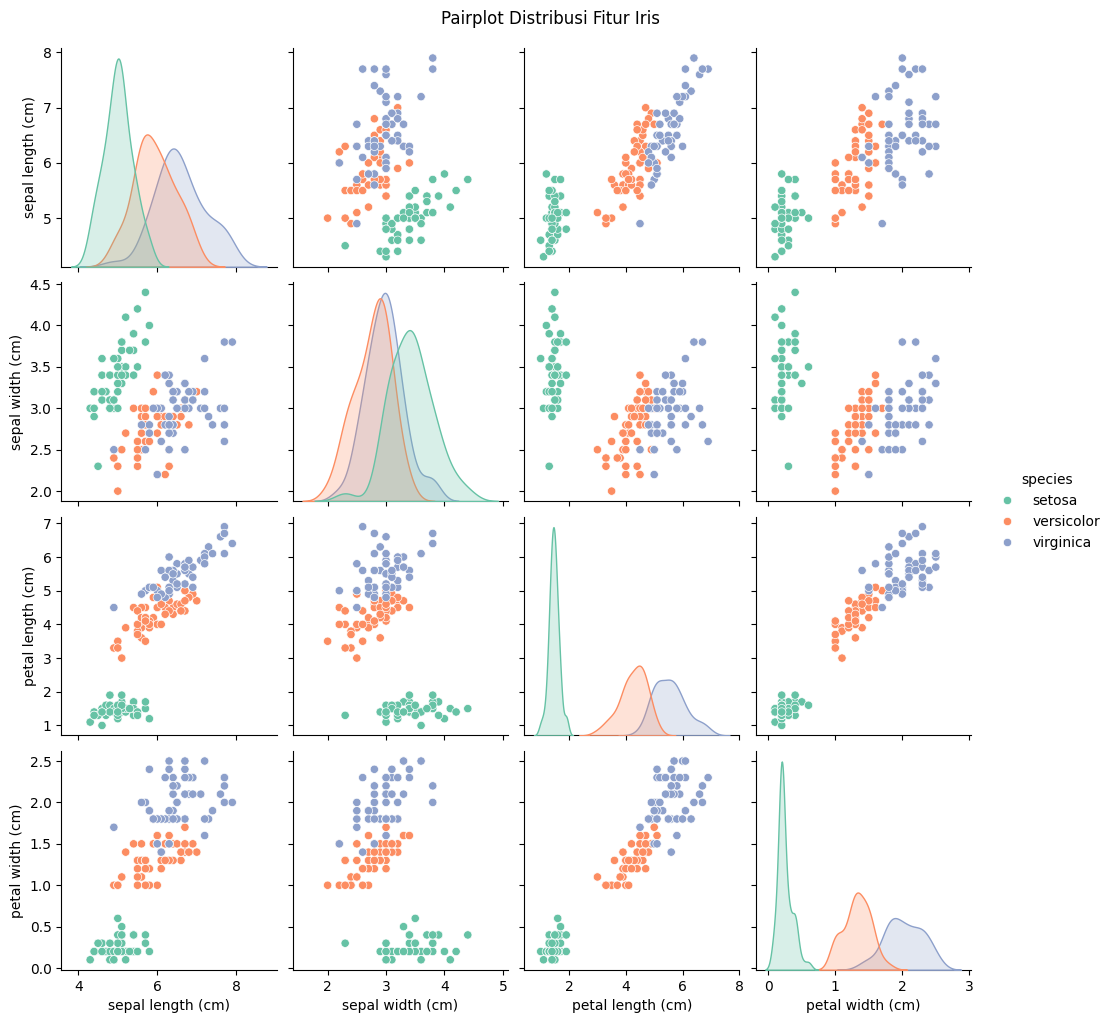

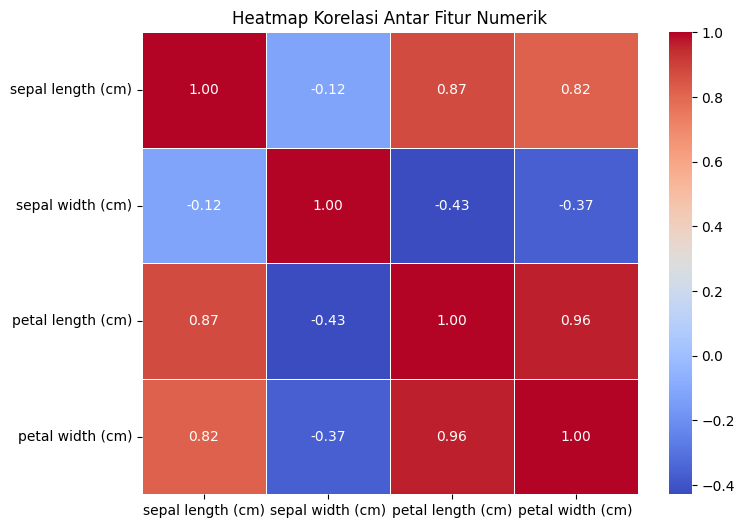

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Tentukan target kolom
target_col = 'Species' if 'Species' in data.columns else 'species'

# Tentukan kolom fitur numerik (mengabaikan Id dan Species)
feature_cols = [col for col in data.columns if col.lower() not in ['id', 'species']]

# 1. Pairplot
sns.pairplot(data[feature_cols + [target_col]], hue=target_col, palette='Set2')
plt.suptitle('Pairplot Distribusi Fitur Iris', y=1.02)
plt.show()

# 2. Heatmap Korelasi untuk Fitur Numerik saja
plt.figure(figsize=(8, 6))
sns.heatmap(data[feature_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Fitur Numerik')
plt.show()

## LANGKAH 4 — PREPROCESSING DATA


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

target_col = 'Species' if 'Species' in data.columns else 'species'
feature_cols = [col for col in data.columns if col.lower() not in ['id', 'species']]

X = data[feature_cols]
y = data[target_col]

# Membagi data menjadi 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# Standardisasi fitur
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)

Ukuran X_train: (105, 4)
Ukuran X_test: (45, 4)


## LANGKAH 5 — MEMBUAT MODEL kNN


In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Inisiasi dan latih model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

print("Model k-Nearest Neighbors (k=3) berhasil dilatih!")

Model k-Nearest Neighbors (k=3) berhasil dilatih!


## LANGKAH 6 — EVALUASI MODEL kNN



Akurasi Model: 100.00%

Laporan Klasifikasi:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



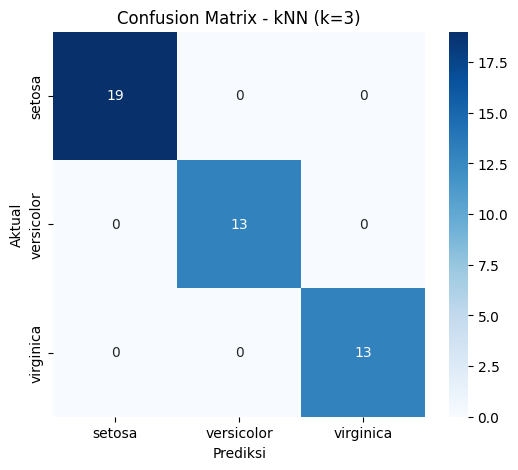

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Prediksi data uji
y_pred = knn.predict(X_test)

# Tampilkan hasil evaluasi
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
labels = sorted(list(y.unique()))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - kNN (k=3)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## LANGKAH 7 — MENCARI NILAI k TERBAIK


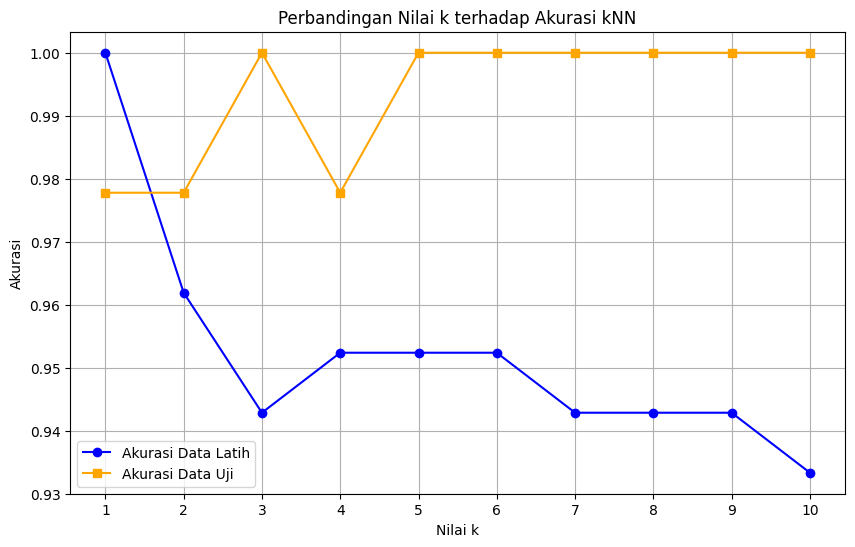

In [8]:
acc_test = []
acc_train = []
k_values = range(1, 11)

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    acc_train.append(model.score(X_train, y_train))
    acc_test.append(model.score(X_test, y_test))

# Visualisasi perbandingan nilai k terhadap akurasi
plt.figure(figsize=(10, 6))
plt.plot(list(k_values), acc_train, marker='o', label='Akurasi Data Latih', color='blue')
plt.plot(list(k_values), acc_test, marker='s', label='Akurasi Data Uji', color='orange')

plt.title('Perbandingan Nilai k terhadap Akurasi kNN')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

## LANGKAH 8 & 9 — ANALISIS & KESIMPULAN

### Analisis Hasil
*   **Akurasi Model k=3**: Perhatikan akurasi yang diperoleh pada Langkah 6. kNN mampu mengklasifikasikan spesies bunga Iris dengan presisi sangat baik.
*   **Analisis Kelas**: Melalui visualisasi Pairplot dan Confusion Matrix, kita dapat mengamati spesies mana yang sangat mudah dipisahkan (biasanya Setosa terpisah secara linear dengan jelas) dan spesies mana yang memiliki sedikit tumpang tindih (Versicolor dan Virginica).
*   **Grafik Nilai k**: Plot akurasi data latih vs data uji menunjukkan tren bagaimana perubahan nilai tetangga (`k`) mempengaruhi generalisasi model. Nilai `k` yang terlalu kecil rentan terhadap overfitting, sementara `k` yang terlalu besar rentan terhadap underfitting.

### Kesimpulan Praktikum
1.  **Algoritma kNN** sukses diimplementasikan untuk melakukan klasifikasi spesies bunga Iris.
2.  **Standardisasi data** sangat krusial dalam algoritma berbasis jarak seperti kNN agar fitur dengan skala besar tidak mendominasi perhitungan jarak.
3.  Grafik pencarian nilai `k` membantu menentukan parameter terbaik untuk menghindari bias dan varians tinggi pada model.

# Praktikum 2: Klasifikasi Naive Bayes dengan Data Dummy



## LANGKAH 1 — MEMBUAT DATASET DUMMY



In [9]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
X, y = make_classification(
    n_samples=30,
    n_features=2,
    n_classes=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    shuffle=False,
    random_state=42
)

# Mengubah nilai fitur menjadi absolut (non-negatif)
X = np.absolute(X)

# Membulatkan nilai dan mengalikannya dengan 100
X = np.round(X, 2) * 100

# Mengubah fitur menjadi integer
X = X.astype(int)

# Menampilkan hasil
print("Data fitur X (30 sampel, 2 fitur):")
print(X)

print("\nLabel y:")
print(y)

Data fitur X (30 sampel, 2 fitur):
[[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]
 [ 50 142]
 [206 110]
 [115  84]
 [124  66]
 [150  85]
 [ 16  73]
 [ 46 113]
 [ 26  80]
 [ 18 114]
 [211 154]
 [ 53  66]
 [ 93 109]
 [175 172]
 [ 80  85]
 [111 125]
 [115 105]
 [ 66  92]
 [160  85]
 [ 53 106]
 [122  85]]

Label y:
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


## LANGKAH 2 — MEMBUAT DATAFRAME



In [10]:
import pandas as pd

# Mengubah label menjadi array dua dimensi agar bisa digabung
y_new = y.reshape(len(y), 1)

# Menggabungkan fitur dan label
data_dummy = np.concatenate((X, y_new), axis=1)

# Memberi nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Membuat DataFrame
df = pd.DataFrame(data_dummy, columns=nama_kolom)

# Menampilkan 5 data pertama
print("=== Lima Baris Pertama ===")
display(df.head())

# Jumlah baris dan kolom
print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}\n")

# Informasi tipe data
print("=== Informasi Tipe Data ===")
df.info()

# Statistik deskriptif
print("\n=== Statistik Deskriptif ===")
display(df.describe())

# Distribusi kelas
print("=== Distribusi Jumlah Sampel Per Label ===")
print(df['Label'].value_counts())

=== Lima Baris Pertama ===


,Fitur 1,Fitur 2,Label
0,112,139,0
1,179,210,0
2,83,71,0
3,182,265,0
4,105,78,0


Jumlah baris: 30, Jumlah kolom: 3

=== Informasi Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Fitur 1  30 non-null     int64
 1   Fitur 2  30 non-null     int64
 2   Label    30 non-null     int64
dtypes: int64(3)
memory usage: 852.0 bytes

=== Statistik Deskriptif ===


,Fitur 1,Fitur 2,Label
count,30.000000,30.000000,30.000000
mean,104.866667,104.466667,0.500000
std,62.942082,47.264285,0.508548
min,16.000000,43.000000,0.000000
25%,53.000000,74.250000,0.000000
50%,108.000000,85.000000,0.500000
75%,143.500000,113.750000,1.000000
max,250.000000,265.000000,1.000000


=== Distribusi Jumlah Sampel Per Label ===
Label
0    15
1    15
Name: count, dtype: int64


## LANGKAH 3 — LABELING (MAPPING KELAS)



In [11]:
labels = {
    1: 'Kelas A',
    0: 'Kelas B'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

print("=== DataFrame dengan Label Kategorikal ===")
display(df_label.head())

=== DataFrame dengan Label Kategorikal ===


,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


## LANGKAH 4 — VISUALISASI DATA



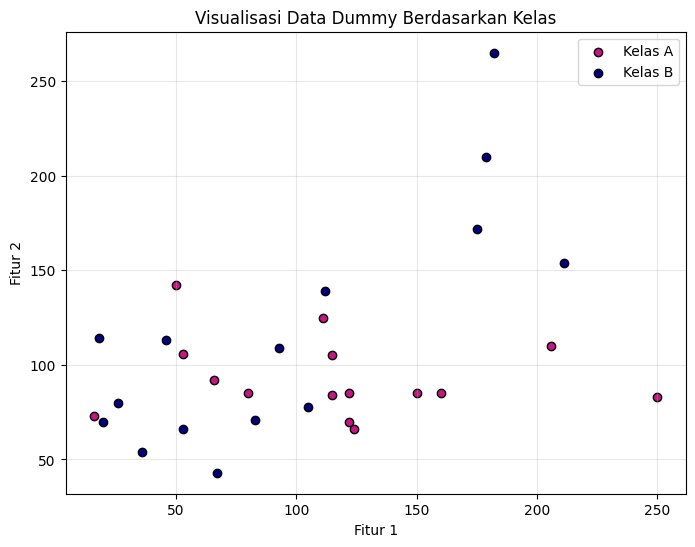

In [12]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

gb = df_label.groupby('Label')

class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.figure(figsize=(8, 6))

plt.scatter(
    class_a['Fitur 1'],
    class_a['Fitur 2'],
    c=colors['class_a'],
    label='Kelas A',
    edgecolors='black'
)

plt.scatter(
    class_b['Fitur 1'],
    class_b['Fitur 2'],
    c=colors['class_b'],
    label='Kelas B',
    edgecolors='black'
)

plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Visualisasi Data Dummy Berdasarkan Kelas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## LANGKAH 5 — MEMBAGI DATA TRAINING DAN TESTING



In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=30
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 21
Jumlah data testing: 9


## LANGKAH 6 — MODEL MULTINOMIAL NAIVE BAYES


In [14]:
from sklearn.naive_bayes import MultinomialNB

# Inisialisasi model
mnb = MultinomialNB()

# Melatih model
mnb.fit(X_train, y_train)

# Prediksi data training dan testing
y_train_pred_mnb = mnb.predict(X_train)
y_test_pred_mnb = mnb.predict(X_test)

# Menghitung akurasi
acc_train_mnb = accuracy_score(y_train, y_train_pred_mnb)
acc_test_mnb = accuracy_score(y_test, y_test_pred_mnb)

print("Hasil akurasi data train (Multinomial):", acc_train_mnb)
print("Hasil akurasi data test (Multinomial):", acc_test_mnb)

Hasil akurasi data train (Multinomial): 0.8095238095238095
Hasil akurasi data test (Multinomial): 0.3333333333333333


## LANGKAH 7 — MODEL GAUSSIAN NAIVE BAYES



In [15]:
from sklearn.naive_bayes import GaussianNB

# Inisialisasi model
gnb = GaussianNB()

# Melatih model
gnb.fit(X_train, y_train)

# Prediksi data training dan testing
y_train_pred_gnb = gnb.predict(X_train)
y_test_pred_gnb = gnb.predict(X_test)

# Menghitung akurasi
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print("Hasil akurasi data train (Gaussian):", acc_train_gnb)
print("Hasil akurasi data test (Gaussian):", acc_test_gnb)

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.4444444444444444


## LANGKAH 8 — MEMBANDINGKAN KEDUA MODEL



,Model,Akurasi Training,Akurasi Testing
0,Multinomial Naive Bayes,0.809524,0.333333
1,Gaussian Naive Bayes,0.857143,0.444444


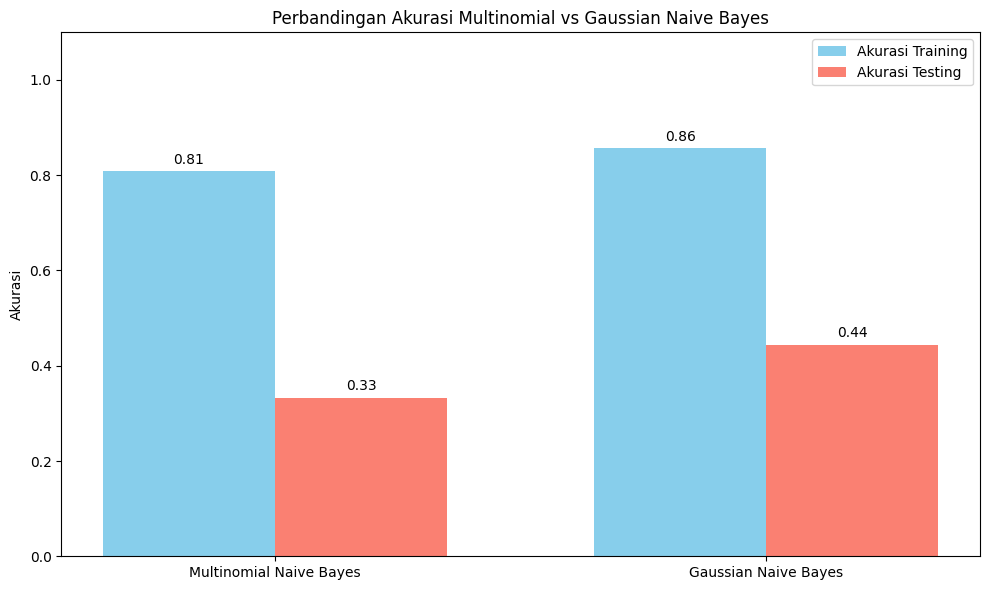

In [16]:
hasil_nb = pd.DataFrame({
    'Model': [
        'Multinomial Naive Bayes',
        'Gaussian Naive Bayes'
    ],
    'Akurasi Training': [
        acc_train_mnb,
        acc_train_gnb
    ],
    'Akurasi Testing': [
        acc_test_mnb,
        acc_test_gnb
    ]
})

display(hasil_nb)

# Visualisasi Bar Plot
fig, ax = plt.subplots(figsize=(10, 6))
x_indices = np.arange(len(hasil_nb['Model']))
bar_width = 0.35

rects1 = ax.bar(x_indices - bar_width/2, hasil_nb['Akurasi Training'], bar_width, label='Akurasi Training', color='skyblue')
rects2 = ax.bar(x_indices + bar_width/2, hasil_nb['Akurasi Testing'], bar_width, label='Akurasi Testing', color='salmon')

ax.set_ylabel('Akurasi')
ax.set_title('Perbandingan Akurasi Multinomial vs Gaussian Naive Bayes')
ax.set_xticks(x_indices)
ax.set_xticklabels(hasil_nb['Model'])
ax.set_ylim(0, 1.1)
ax.legend()

# Menambahkan nilai di atas batang
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # offset vertikal
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

## LANGKAH 9 & 10 — ANALISIS HASIL & KESIMPULAN

### Analisis Hasil
*   **Karakteristik Data**: Data dummy yang dibuat memiliki rentang integer non-negatif. Melalui scatter plot, kita dapat melihat apakah sebaran antarkelas cenderung tumpang-tindih atau terpisah jelas.
*   **Perbandingan Model**: Bandingkan skor akurasi antara Multinomial Naive Bayes dan Gaussian Naive Bayes di atas. Karena jumlah data sangat sedikit (30 sampel, dengan 9 sampel sebagai testing), pergeseran kecil atau pola khusus di dalam dataset dummy ini sangat memengaruhi performa akurasi.
*   **Keterbatasan**: Hasil evaluasi ini sangat dipengaruhi oleh parameter penentu data dummy (`random_state`) dan konfigurasi data pemisah.

### Kesimpulan Praktikum 2
1.  **Tujuan Tercapai**: Kita telah sukses mengimplementasikan dan memahami konsep klasifikasi menggunakan MultinomialNB dan GaussianNB.
2.  **Pembuatan Data Dummy**: Menggunakan `make_classification()` memungkinkan kita menguji model secara cepat tanpa bergantung pada dataset eksternal.
3.  **Karakteristik Model**: GaussianNB secara teoritis lebih optimal menangani data kontinu yang dimodelkan dengan kurva lonceng, sedangkan MultinomialNB bekerja dengan distribusi multinomial (perhitungan kemunculan).

# Praktikum 3: Klasifikasi Teks SMS dengan Multinomial Naive Bayes dan Bag of Words



## LANGKAH 1 — LOAD DATA



In [17]:
import numpy as np
import pandas as pd
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Memeriksa keberadaan file spam.csv
if not os.path.exists('spam.csv'):
    if IN_COLAB:
        print("Silakan unggah file spam.csv:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File spam.csv tidak ditemukan. Letakkan di folder yang sama dengan notebook ini.")

# Membaca dataset
df_spam = pd.read_csv('spam.csv', encoding='latin-1')

# Menampilkan 5 baris pertama
display(df_spam.head())

Silakan unggah file spam.csv:


Saving spam.csv to spam.csv


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## LANGKAH 2 — PREPROCESSING DATA


In [18]:
# Mempertahankan dua kolom utama saja
df_spam = df_spam.iloc[:, :2].copy()

display(df_spam.head())

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2B: Mengubah nama kolom


In [19]:
df_spam.columns = ['Labels', 'SMS']

display(df_spam.head())

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2C: Inspeksi data


In [20]:
print("Jumlah data per kelas:")
print(df_spam['Labels'].value_counts())

print("\nInformasi dataset:")
df_spam.info()

print("\nStatistik deskriptif:")
display(df_spam.describe())

print("\nNilai kosong:")
print(df_spam.isnull().sum())

print("\nJumlah data duplikat:")
print(df_spam.duplicated().sum())

Jumlah data per kelas:
Labels
ham     4825
spam     747
Name: count, dtype: int64

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Statistik deskriptif:


,Labels,SMS
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



Nilai kosong:
Labels    0
SMS       0
dtype: int64

Jumlah data duplikat:
403


### Langkah 2D: Encoding label


In [21]:
new_labels = {
    'spam': 1,
    'ham': 0
}

df_spam['Labels'] = df_spam['Labels'].map(new_labels)

display(df_spam.head())

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


### Langkah 2E: Memisahkan fitur dan label


In [22]:
X_sms = df_spam['SMS'].values
y_sms = df_spam['Labels'].values

print("X_sms (contoh teks kesatu):", X_sms[0])
print("y_sms (contoh label kesatu):", y_sms[0])

X_sms (contoh teks kesatu): Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
y_sms (contoh label kesatu): 0


## LANGKAH 3 — PEMBAGIAN DATA DAN EKSTRAKSI FITUR


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data 80% train, 20% test
X_train_sms, X_test_sms, y_train_sms, y_test_sms = train_test_split(
    X_sms,
    y_sms,
    test_size=0.2,
    random_state=50
)

bow = CountVectorizer()

# Fit dan transform hanya pada data training, transform saja pada data testing
X_train_bow = bow.fit_transform(X_train_sms)
X_test_bow = bow.transform(X_test_sms)

print("Jumlah fitur kata:", len(bow.get_feature_names_out()))
print("Dimensi data training:", X_train_bow.shape)
print("Dimensi data testing:", X_test_bow.shape)

# Menampilkan beberapa fitur kata contoh
print("\nBeberapa fitur kata:", list(bow.get_feature_names_out()[1000:1015]))

Jumlah fitur kata: 7727
Dimensi data training: (4457, 7727)
Dimensi data testing: (1115, 7727)

Beberapa fitur kata: ['appreciate', 'appreciated', 'approaching', 'appropriate', 'approve', 'approved', 'approx', 'apps', 'appt', 'appy', 'april', 'aproach', 'aptitude', 'aquarius', 'ar']


## LANGKAH 4 — TRAINING MODEL MULTINOMIAL NAIVE BAYES



In [24]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

mnb_sms = MultinomialNB()
mnb_sms.fit(X_train_bow, y_train_sms)

y_pred_train_sms = mnb_sms.predict(X_train_bow)
y_pred_test_sms = mnb_sms.predict(X_test_bow)

acc_train_sms = accuracy_score(y_train_sms, y_pred_train_sms)
acc_test_sms = accuracy_score(y_test_sms, y_pred_test_sms)

print(f'Hasil akurasi data train: {acc_train_sms:.5f}')
print(f'Hasil akurasi data test: {acc_test_sms:.5f}')

Hasil akurasi data train: 0.99462
Hasil akurasi data test: 0.97758


## LANGKAH 5 — EVALUASI TAMBAHAN



Confusion Matrix:
[[951   3]
 [ 22 139]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.86      0.92       161

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



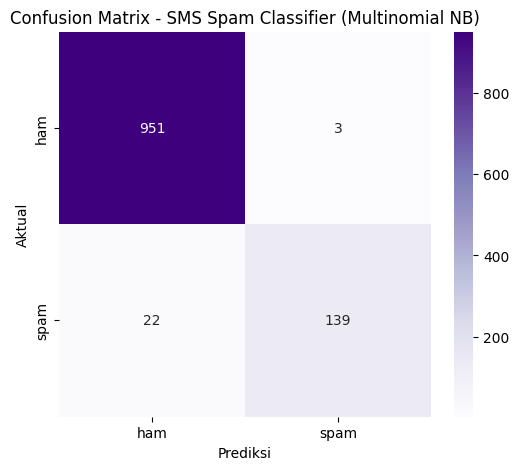

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
cm_sms = confusion_matrix(y_test_sms, y_pred_test_sms)
print(cm_sms)

print("\nLaporan Klasifikasi:")
print(
    classification_report(
        y_test_sms,
        y_pred_test_sms,
        target_names=['ham', 'spam'],
        zero_division=0
    )
)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_sms, annot=True, fmt='d', cmap='Purples', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - SMS Spam Classifier (Multinomial NB)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## LANGKAH 6 & 7 — ANALISIS HASIL & KESIMPULAN

### Analisis Hasil
*   **Akurasi Model**: Perhatikan akurasi training dan testing yang diperoleh pada Langkah 4. Model Naive Bayes sangat andal dalam klasifikasi teks berbasis kata.
*   **Analisis Confusion Matrix**:
    *   **True Negative (TN)**: SMS ham yang terprediksi benar sebagai ham.
    *   **False Positive (FP)**: SMS ham yang salah terprediksi sebagai spam.
    *   **False Negative (FN)**: SMS spam yang lolos dari filter dan salah diklasifikasikan sebagai ham.
    *   **True Positive (TP)**: SMS spam yang terprediksi benar sebagai spam.
*   **Evaluasi Tambahan**: Nilai precision, recall, dan f1-score membantu mengonfirmasi ketahanan model di tengah dataset yang tidak seimbang (imbalanced dataset).

### Kesimpulan Praktikum 3
1.  **Tujuan Tercapai**: Klasifikasi teks SMS Spam menggunakan Multinomial Naive Bayes dan representasi Bag of Words telah sukses dilakukan.
2.  **Representasi Kata**: `CountVectorizer` terbukti sangat efisien dalam mereduksi teks mentah menjadi fitur matriks numerik yang siap dikonsumsi oleh algoritma klasifikasi.
3.  **Keterbatasan**: Pendekatan Bag of Words mengabaikan urutan kata (konteks kalimat). Walaupun akurasi tinggi, beberapa kata di luar kamus latihan (Out-Of-Vocabulary) dapat memengaruhi performa deteksi real-time.

# TUGAS 1: Klasifikasi Jenis Suara (male/female) dengan kNN pada `voice.csv`

**Nama:** Maulidya Afriani  
**NIM:** 244107020059  

### Soal
1. Membuat model klasifikasi kNN untuk mengklasifikasikan jenis suara `male` dan `female` pada dataset `voice.csv`.
2. Melakukan percobaan untuk mengetahui fitur-fitur yang paling optimal, lalu menyebutkan fitur apa saja yang menghasilkan hasil terbaik.
3. Berdasarkan fitur terpilih, menentukan nilai `k` terbaik, dilengkapi grafik analisis dan alasan.

**Strategi:** seluruh pemilihan fitur dan nilai `k` dilakukan menggunakan *cross-validation* pada **data latih saja**. Data uji hanya dipakai sekali di akhir untuk evaluasi, supaya hasilnya tidak bias.

In [26]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists('voice.csv'):
    if IN_COLAB:
        print("Silakan unggah file voice.csv:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File voice.csv tidak ditemukan. Letakkan di folder yang sama dengan notebook ini.")

voice = pd.read_csv('voice.csv')

print("Ukuran data:", voice.shape)
display(voice.head())

# Mencari kolom target (label) secara otomatis
label_col = [c for c in voice.columns if c.lower() == 'label'][0]
print("\nKolom target:", label_col)
print(voice[label_col].value_counts())

Silakan unggah file voice.csv:


Saving voice.csv to voice.csv
Ukuran data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male



Kolom target: label
label
male      1584
female    1584
Name: count, dtype: int64


## LANGKAH 2 — EKSPLORASI DATA

In [27]:
voice.info()

print("\nNilai kosong per kolom:")
print(voice.isnull().sum().sum(), "nilai kosong secara total")
print("Jumlah data duplikat:", voice.duplicated().sum())

display(voice.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


## LANGKAH 3 — PREPROCESSING & PEMBAGIAN DATA

In [28]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

fitur_semua = [c for c in voice.columns if c != label_col]
X = voice[fitur_semua]
y = voice[label_col].str.lower().map({'male': 1, 'female': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def buat_pipeline(k=5):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

print("Jumlah fitur :", len(fitur_semua))
print("Data latih   :", X_train.shape[0])
print("Data uji     :", X_test.shape[0])

Jumlah fitur : 20
Data latih   : 2534
Data uji     : 634


## LANGKAH 4 — MODEL kNN DASAR (SEMUA FITUR)  → *Soal 1*

In [29]:
base = buat_pipeline(k=5)
base.fit(X_train, y_train)

acc_base_train = base.score(X_train, y_train)
acc_base_cv = cross_val_score(buat_pipeline(5), X_train, y_train, cv=cv).mean()
acc_base_test = base.score(X_test, y_test)

print(f"[Baseline - semua {len(fitur_semua)} fitur, k=5]")
print(f"Akurasi latih          : {acc_base_train:.4f}")
print(f"Akurasi CV (data latih): {acc_base_cv:.4f}")
print(f"Akurasi uji            : {acc_base_test:.4f}")

[Baseline - semua 20 fitur, k=5]
Akurasi latih          : 0.9830
Akurasi CV (data latih): 0.9696
Akurasi uji            : 0.9763


## LANGKAH 5 — PERCOBAAN PEMILIHAN FITUR OPTIMAL  → *Soal 2*

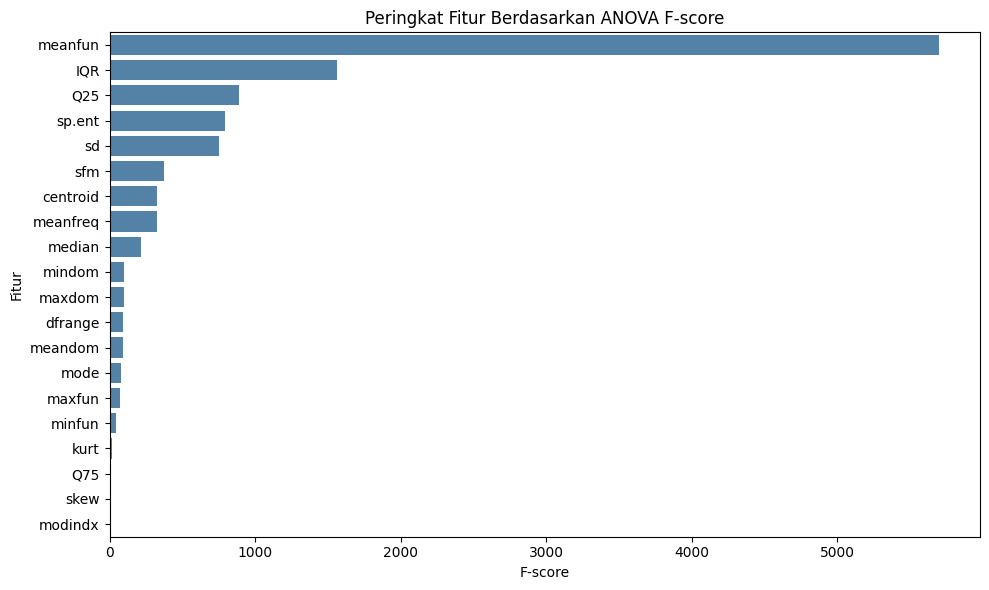

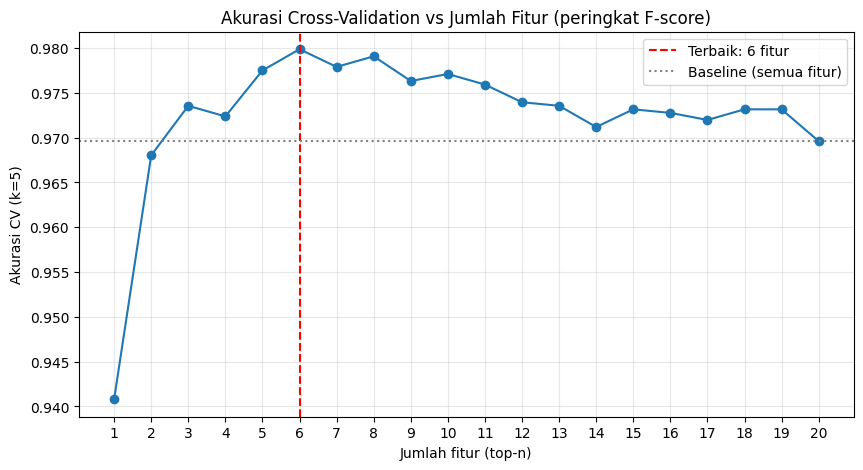

Jumlah fitur terbaik (metode filter): 6
Akurasi CV                          : 0.9799
Fitur terpilih: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


In [30]:
from sklearn.feature_selection import f_classif

# ---- A. Peringkat fitur berdasarkan F-score (hanya dari data latih) ----
f_scores, _ = f_classif(X_train, y_train)
skor_fitur = pd.Series(f_scores, index=fitur_semua).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=skor_fitur.values, y=skor_fitur.index, color='steelblue')
plt.title('Peringkat Fitur Berdasarkan ANOVA F-score')
plt.xlabel('F-score')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

# Akurasi CV untuk top-n fitur
urutan_fitur = list(skor_fitur.index)
hasil_n = []
for n in range(1, len(urutan_fitur) + 1):
    kolom = urutan_fitur[:n]
    skor_cv = cross_val_score(buat_pipeline(5), X_train[kolom], y_train, cv=cv).mean()
    hasil_n.append(skor_cv)

n_terbaik = int(np.argmax(hasil_n)) + 1
fitur_filter = urutan_fitur[:n_terbaik]

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(hasil_n) + 1), hasil_n, marker='o')
plt.axvline(n_terbaik, color='red', linestyle='--', label=f'Terbaik: {n_terbaik} fitur')
plt.axhline(acc_base_cv, color='gray', linestyle=':', label='Baseline (semua fitur)')
plt.title('Akurasi Cross-Validation vs Jumlah Fitur (peringkat F-score)')
plt.xlabel('Jumlah fitur (top-n)')
plt.ylabel('Akurasi CV (k=5)')
plt.xticks(range(1, len(hasil_n) + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Jumlah fitur terbaik (metode filter): {n_terbaik}")
print(f"Akurasi CV                          : {max(hasil_n):.4f}")
print("Fitur terpilih:", fitur_filter)

In [31]:
from sklearn.feature_selection import SequentialFeatureSelector

# ---- B. Sequential Forward Selection dengan jumlah fitur yang sama ----
sfs = SequentialFeatureSelector(
    buat_pipeline(5),
    n_features_to_select=n_terbaik,
    direction='forward',
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)
sfs.fit(X_train, y_train)
fitur_sfs = [str(f) for f in np.array(fitur_semua)[sfs.get_support()]]

acc_filter_cv = cross_val_score(buat_pipeline(5), X_train[fitur_filter], y_train, cv=cv).mean()
acc_sfs_cv = cross_val_score(buat_pipeline(5), X_train[fitur_sfs], y_train, cv=cv).mean()

perbandingan = pd.DataFrame({
    'Metode': ['Semua fitur (baseline)', 'Filter (F-score)', 'Wrapper (Forward Selection)'],
    'Jumlah Fitur': [len(fitur_semua), len(fitur_filter), len(fitur_sfs)],
    'Akurasi CV': [acc_base_cv, acc_filter_cv, acc_sfs_cv]
})
display(perbandingan)

print("Fitur metode filter :", fitur_filter)
print("Fitur metode wrapper:", fitur_sfs)

# Pilih himpunan fitur dengan akurasi CV tertinggi (jika sama, pilih metode filter)
if acc_sfs_cv > max(acc_filter_cv, acc_base_cv):
    fitur_terpilih, metode_terpilih = fitur_sfs, 'Forward Selection'
elif acc_filter_cv >= acc_base_cv:
    fitur_terpilih, metode_terpilih = fitur_filter, 'Filter (F-score)'
else:
    fitur_terpilih, metode_terpilih = fitur_semua, 'Semua fitur'

print(f"\n>>> FITUR OPTIMAL (metode: {metode_terpilih}), {len(fitur_terpilih)} fitur:")
print(fitur_terpilih)

,Metode,Jumlah Fitur,Akurasi CV
0,Semua fitur (baseline),20,0.969609
1,Filter (F-score),6,0.979872
2,Wrapper (Forward Selection),6,0.981057


Fitur metode filter : ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']
Fitur metode wrapper: ['IQR', 'skew', 'kurt', 'sfm', 'mode', 'meanfun']

>>> FITUR OPTIMAL (metode: Forward Selection), 6 fitur:
['IQR', 'skew', 'kurt', 'sfm', 'mode', 'meanfun']


## LANGKAH 6 — MENENTUKAN NILAI k TERBAIK  → *Soal 3*


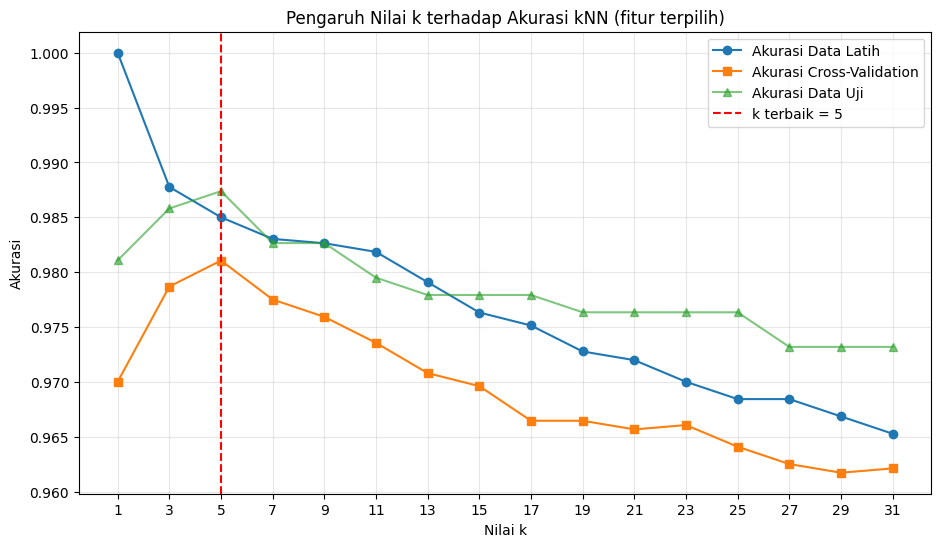

Nilai k terbaik (berdasarkan akurasi CV): 5
Akurasi CV pada k terbaik               : 0.9811


In [32]:
k_list = list(range(1, 32, 2))
acc_tr, acc_cv, acc_te = [], [], []

for k in k_list:
    pipe = buat_pipeline(k).fit(X_train[fitur_terpilih], y_train)
    acc_tr.append(pipe.score(X_train[fitur_terpilih], y_train))
    acc_te.append(pipe.score(X_test[fitur_terpilih], y_test))
    acc_cv.append(cross_val_score(buat_pipeline(k), X_train[fitur_terpilih], y_train, cv=cv).mean())

k_terbaik = k_list[int(np.argmax(acc_cv))]

plt.figure(figsize=(11, 6))
plt.plot(k_list, acc_tr, marker='o', label='Akurasi Data Latih')
plt.plot(k_list, acc_cv, marker='s', label='Akurasi Cross-Validation')
plt.plot(k_list, acc_te, marker='^', label='Akurasi Data Uji', alpha=0.6)
plt.axvline(k_terbaik, color='red', linestyle='--', label=f'k terbaik = {k_terbaik}')
plt.title('Pengaruh Nilai k terhadap Akurasi kNN (fitur terpilih)')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_list)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Nilai k terbaik (berdasarkan akurasi CV): {k_terbaik}")
print(f"Akurasi CV pada k terbaik               : {max(acc_cv):.4f}")

## LANGKAH 7 — EVALUASI MODEL AKHIR

Akurasi data uji (model akhir): 0.9874
Akurasi data uji (baseline)   : 0.9763

Laporan Klasifikasi:
              precision    recall  f1-score   support

      female       0.99      0.98      0.99       317
        male       0.98      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



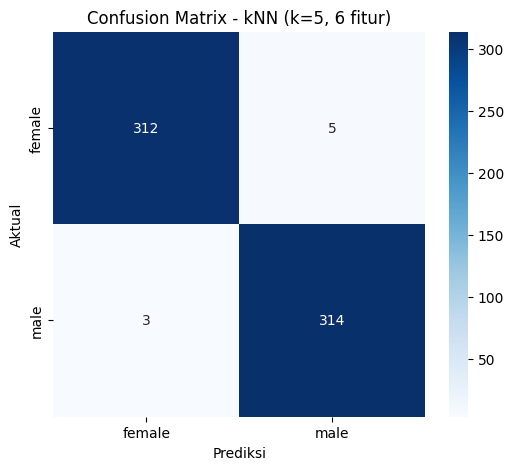

In [33]:
model_akhir = buat_pipeline(k_terbaik).fit(X_train[fitur_terpilih], y_train)
y_pred = model_akhir.predict(X_test[fitur_terpilih])

acc_akhir = accuracy_score(y_test, y_pred)
print(f"Akurasi data uji (model akhir): {acc_akhir:.4f}")
print(f"Akurasi data uji (baseline)   : {acc_base_test:.4f}")

print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['female', 'male'], yticklabels=['female', 'male'])
plt.title(f'Confusion Matrix - kNN (k={k_terbaik}, {len(fitur_terpilih)} fitur)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## LANGKAH 8 — RINGKASAN HASIL TUGAS 1 (otomatis dari hasil eksekusi)

In [34]:
print("="*60)
print("RINGKASAN TUGAS 1")
print("="*60)
print(f"1. Model kNN dengan semua fitur (k=5): akurasi uji = {acc_base_test:.4f}")
print(f"2. Fitur optimal ({metode_terpilih}, {len(fitur_terpilih)} fitur):")
for f in fitur_terpilih:
    print("   -", f)
print(f"3. Nilai k terbaik = {k_terbaik} (akurasi CV = {max(acc_cv):.4f})")
print(f"   Akurasi uji model akhir = {acc_akhir:.4f}")
print("="*60)

RINGKASAN TUGAS 1
1. Model kNN dengan semua fitur (k=5): akurasi uji = 0.9763
2. Fitur optimal (Forward Selection, 6 fitur):
   - IQR
   - skew
   - kurt
   - sfm
   - mode
   - meanfun
3. Nilai k terbaik = 5 (akurasi CV = 0.9811)
   Akurasi uji model akhir = 0.9874


## ANALISIS DAN KESIMPULAN TUGAS 1

**Fitur optimal (Soal 2).** Hasil pemilihan fitur ditampilkan pada Langkah 5 dan dirangkum pada Langkah 8. Pada grafik F-score terlihat bahwa hanya sebagian fitur yang benar-benar kuat membedakan suara laki-laki dan perempuan (umumnya fitur terkait frekuensi dasar dan distribusi frekuensi seperti `meanfun`, `IQR`, dan `Q25`). Fitur yang saling berkorelasi tinggi atau kurang informatif cenderung menambah *noise* pada perhitungan jarak kNN, sehingga menambah semua fitur belum tentu menaikkan akurasi.

**Nilai k terbaik (Soal 3).** Nilai `k` dipilih dari titik akurasi cross-validation tertinggi pada grafik Langkah 6. Alasannya:
- `k` yang terlalu kecil (misalnya `k=1`) membuat model terlalu mengikuti data latih (*overfitting*), terlihat dari akurasi latih yang sangat tinggi tetapi akurasi CV lebih rendah.
- `k` yang terlalu besar membuat batas keputusan terlalu halus (*underfitting*), sehingga akurasi CV ikut turun.
- `k` terbaik adalah titik keseimbangan antara keduanya, yaitu akurasi CV tertinggi dengan selisih akurasi latih dan CV yang tidak terlalu jauh.
- Pemilihan memakai CV, bukan data uji, sehingga akurasi data uji tetap menjadi ukuran yang jujur untuk performa pada data baru.

**Kesimpulan.** kNN dengan standardisasi, fitur terpilih, dan `k` hasil tuning mampu mengklasifikasikan jenis suara male/female dengan akurasi tinggi. Pemilihan fitur membuat model lebih ringkas tanpa mengorbankan (bahkan sering meningkatkan) akurasi dibanding memakai semua fitur.

# TUGAS 2: Klasifikasi SMS Spam dengan Multinomial Naive Bayes (`spam.csv`)

**Nama:** Maulidya Afriani  
**NIM:** 244107020059  

### Soal
- **Tugas 2 (a):** Model Multinomial Naive Bayes dengan data `spam.csv`, fitur **CountVectorizer** dengan `stop_words` aktif, lalu evaluasi hasilnya.
- **Tugas 2 (b):** Model Multinomial Naive Bayes dengan data `spam.csv`, fitur **TF-IDF** dengan `stop_words` aktif, evaluasi hasilnya, dan bandingkan dengan hasil Tugas 2 (a).
- **Kesimpulan:** fitur mana yang terbaik pada kasus data `spam.csv`.

Kedua model memakai pembagian data yang **sama** (80% latih, 20% uji, `random_state=50`, `stratify`) supaya perbandingannya adil.

## LANGKAH 1 — LOAD DAN PERSIAPAN DATA

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists('spam.csv'):
    if IN_COLAB:
        print("Silakan unggah file spam.csv:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File spam.csv tidak ditemukan. Letakkan di folder yang sama dengan notebook ini.")

# Dibaca ulang dari awal agar sel ini bisa dijalankan mandiri
spam = pd.read_csv('spam.csv', encoding='latin-1').iloc[:, :2].copy()
spam.columns = ['Labels', 'SMS']
spam['Labels'] = spam['Labels'].map({'spam': 1, 'ham': 0})

print("Ukuran data:", spam.shape)
print("Nilai kosong:", spam.isnull().sum().sum())
print("\nDistribusi kelas (0 = ham, 1 = spam):")
print(spam['Labels'].value_counts())
display(spam.head())

Ukuran data: (5572, 2)
Nilai kosong: 0

Distribusi kelas (0 = ham, 1 = spam):
Labels
0    4825
1     747
Name: count, dtype: int64


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

X_sms = spam['SMS'].values
y_sms = spam['Labels'].values

X_train_sms, X_test_sms, y_train_sms, y_test_sms = train_test_split(
    X_sms, y_sms, test_size=0.2, random_state=50, stratify=y_sms
)

print("Data latih:", len(X_train_sms))
print("Data uji  :", len(X_test_sms))

Data latih: 4457
Data uji  : 1115


## LANGKAH 2 — TUGAS 2 (a): CountVectorizer + `stop_words='english'` + Multinomial NB

Jumlah fitur kata (CountVectorizer + stop_words): 7422

Akurasi data latih: 0.9939
Akurasi data uji  : 0.9821

Laporan Klasifikasi (CountVectorizer):
              precision    recall  f1-score   support

         ham     0.9856    0.9938    0.9897       966
        spam     0.9574    0.9060    0.9310       149

    accuracy                         0.9821      1115
   macro avg     0.9715    0.9499    0.9604      1115
weighted avg     0.9819    0.9821    0.9819      1115



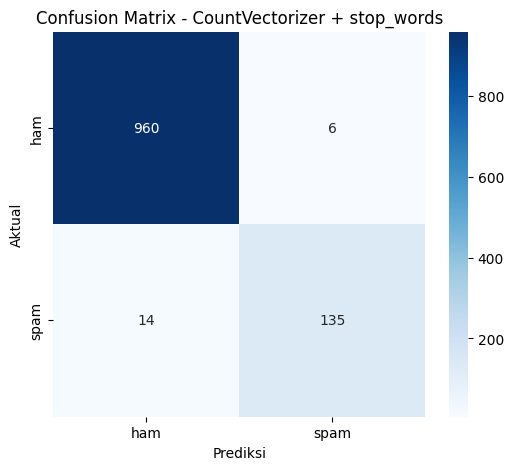

In [37]:
cv_vec = CountVectorizer(stop_words='english')
X_train_cv = cv_vec.fit_transform(X_train_sms)
X_test_cv = cv_vec.transform(X_test_sms)

print("Jumlah fitur kata (CountVectorizer + stop_words):", X_train_cv.shape[1])

nb_cv = MultinomialNB()
nb_cv.fit(X_train_cv, y_train_sms)

pred_train_cv = nb_cv.predict(X_train_cv)
pred_test_cv = nb_cv.predict(X_test_cv)

print(f"\nAkurasi data latih: {accuracy_score(y_train_sms, pred_train_cv):.4f}")
print(f"Akurasi data uji  : {accuracy_score(y_test_sms, pred_test_cv):.4f}")
print("\nLaporan Klasifikasi (CountVectorizer):")
print(classification_report(y_test_sms, pred_test_cv, target_names=['ham', 'spam'], digits=4))

cm_cv = confusion_matrix(y_test_sms, pred_test_cv)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - CountVectorizer + stop_words')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## LANGKAH 3 — TUGAS 2 (b): TF-IDF + `stop_words='english'` + Multinomial NB

Jumlah fitur kata (TF-IDF + stop_words): 7422

Akurasi data latih: 0.9843
Akurasi data uji  : 0.9731

Laporan Klasifikasi (TF-IDF):
              precision    recall  f1-score   support

         ham     0.9699    1.0000    0.9847       966
        spam     1.0000    0.7987    0.8881       149

    accuracy                         0.9731      1115
   macro avg     0.9849    0.8993    0.9364      1115
weighted avg     0.9739    0.9731    0.9718      1115



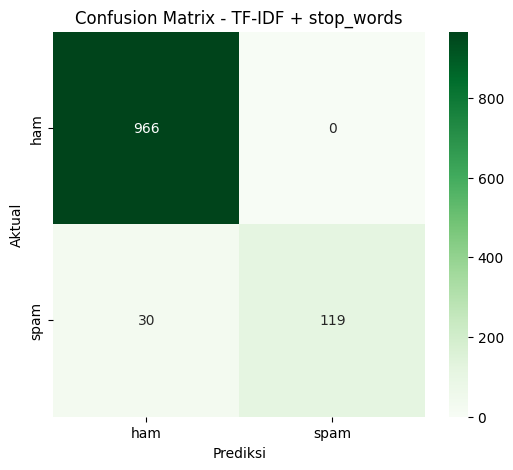

In [38]:
tfidf_vec = TfidfVectorizer(stop_words='english')
X_train_tf = tfidf_vec.fit_transform(X_train_sms)
X_test_tf = tfidf_vec.transform(X_test_sms)

print("Jumlah fitur kata (TF-IDF + stop_words):", X_train_tf.shape[1])

nb_tf = MultinomialNB()
nb_tf.fit(X_train_tf, y_train_sms)

pred_train_tf = nb_tf.predict(X_train_tf)
pred_test_tf = nb_tf.predict(X_test_tf)

print(f"\nAkurasi data latih: {accuracy_score(y_train_sms, pred_train_tf):.4f}")
print(f"Akurasi data uji  : {accuracy_score(y_test_sms, pred_test_tf):.4f}")
print("\nLaporan Klasifikasi (TF-IDF):")
print(classification_report(y_test_sms, pred_test_tf, target_names=['ham', 'spam'], digits=4))

cm_tf = confusion_matrix(y_test_sms, pred_test_tf)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_tf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - TF-IDF + stop_words')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

## LANGKAH 4 — PERBANDINGAN CountVectorizer vs TF-IDF

,Akurasi,Precision (spam),Recall (spam),F1-score (spam)
CountVectorizer + stop_words,0.9821,0.9574,0.9060,0.9310
TF-IDF + stop_words,0.9731,1.0000,0.7987,0.8881


CountVectorizer: salah deteksi ham->spam (FP) = 6, spam lolos (FN) = 14
TF-IDF         : salah deteksi ham->spam (FP) = 0, spam lolos (FN) = 30


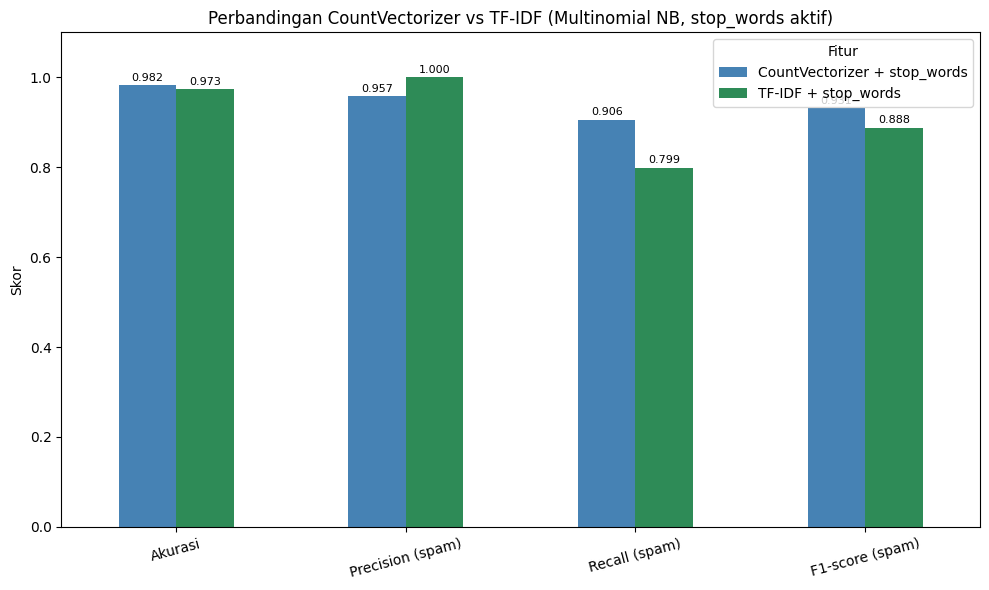

In [39]:
def metrik(y_true, y_pred):
    return {
        'Akurasi': accuracy_score(y_true, y_pred),
        'Precision (spam)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (spam)': recall_score(y_true, y_pred, zero_division=0),
        'F1-score (spam)': f1_score(y_true, y_pred, zero_division=0),
    }

tabel = pd.DataFrame({
    'CountVectorizer + stop_words': metrik(y_test_sms, pred_test_cv),
    'TF-IDF + stop_words': metrik(y_test_sms, pred_test_tf),
}).T
display(tabel.round(4))

# Selisih kesalahan
fp_cv, fn_cv = cm_cv[0, 1], cm_cv[1, 0]
fp_tf, fn_tf = cm_tf[0, 1], cm_tf[1, 0]
print(f"CountVectorizer: salah deteksi ham->spam (FP) = {fp_cv}, spam lolos (FN) = {fn_cv}")
print(f"TF-IDF         : salah deteksi ham->spam (FP) = {fp_tf}, spam lolos (FN) = {fn_tf}")

# Grafik perbandingan
ax = tabel.T.plot(kind='bar', figsize=(10, 6), color=['steelblue', 'seagreen'])
ax.set_title('Perbandingan CountVectorizer vs TF-IDF (Multinomial NB, stop_words aktif)')
ax.set_ylabel('Skor')
ax.set_ylim(0, 1.1)
plt.xticks(rotation=15)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', padding=2, fontsize=8)
plt.legend(title='Fitur')
plt.tight_layout()
plt.show()

## LANGKAH 5 — KESIMPULAN OTOMATIS: FITUR TERBAIK

In [40]:
f1_cv = tabel.loc['CountVectorizer + stop_words', 'F1-score (spam)']
f1_tf = tabel.loc['TF-IDF + stop_words', 'F1-score (spam)']
acc_cv_ = tabel.loc['CountVectorizer + stop_words', 'Akurasi']
acc_tf_ = tabel.loc['TF-IDF + stop_words', 'Akurasi']

if f1_tf > f1_cv:
    terbaik = 'TF-IDF'
elif f1_cv > f1_tf:
    terbaik = 'CountVectorizer'
else:
    terbaik = 'TF-IDF' if acc_tf_ > acc_cv_ else ('CountVectorizer' if acc_cv_ > acc_tf_ else 'keduanya setara')

print("="*60)
print("KESIMPULAN TUGAS 2")
print("="*60)
print(f"CountVectorizer : akurasi = {acc_cv_:.4f} | F1 spam = {f1_cv:.4f}")
print(f"TF-IDF          : akurasi = {acc_tf_:.4f} | F1 spam = {f1_tf:.4f}")
print(f"\nFitur terbaik pada data spam.csv (berdasarkan F1-score spam, lalu akurasi): {terbaik}")
print("="*60)

KESIMPULAN TUGAS 2
CountVectorizer : akurasi = 0.9821 | F1 spam = 0.9310
TF-IDF          : akurasi = 0.9731 | F1 spam = 0.8881

Fitur terbaik pada data spam.csv (berdasarkan F1-score spam, lalu akurasi): CountVectorizer


## ANALISIS DAN KESIMPULAN TUGAS 2

**Perbandingan.** Kedua model memakai algoritma, pembagian data, dan `stop_words` yang sama, sehingga perbedaan hasil hanya berasal dari cara membobotkan kata: CountVectorizer memakai jumlah kemunculan kata mentah, sedangkan TF-IDF memakai bobot yang menurunkan pengaruh kata umum dan menaikkan pengaruh kata khas. Skor lengkap ada pada tabel di Langkah 4.

**Cara membaca hasil.**
- Karena data tidak seimbang, nilai **F1-score kelas spam** dan **recall spam** lebih informatif daripada akurasi.
- Recall spam rendah berarti banyak spam lolos ke kotak masuk (*False Negative*).
- Precision spam rendah berarti banyak pesan biasa salah dianggap spam (*False Positive*), yang pada filter SMS biasanya lebih merugikan pengguna.
- Perbedaan antara kedua fitur pada dataset ini umumnya kecil, sehingga selisih beberapa pesan pada confusion matrix perlu dibaca dengan hati-hati.

**Kesimpulan.** Fitur terbaik ditentukan dari hasil eksekusi pada Langkah 5, yaitu fitur dengan F1-score spam tertinggi (dan akurasi sebagai pembanding). Pemakaian `stop_words` membantu kedua model karena membuang kata umum yang tidak membedakan spam dan ham, sehingga fitur yang tersisa lebih berfokus pada kata-kata khas spam seperti *free*, *win*, *txt*, dan *claim*.